# Example 1: cutting patterns for target structures

Every target mesh in `data/` is sliced into contour lines, which become a cutting pattern (overlap $D = (\delta W)^{1/3}$, see the main README) and then the flat cut sheet. Example 3 deploys these sheets with the ribbon model.

Run the notebook from the `examples/` folder. The script `01_target_structures.py` does the same.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore", category = RuntimeWarning)   # fsolve progress warnings of the section lines
import os, importlib
import numpy as np
from common import *   # also puts ../lib on the path

In [2]:
from isolines import isolines
from cutting_pattern import cutting_patern
from cut_mesh import kirigami_mesh, ribbon_widths, face_components, DATA_DIR

TARGETS = ['cone', 'parabole', 'offcenter', 'trumpet', 'free_curve']
LEVELS = 15     # number of contour lines
TOP = 0.9       # height of the top contour, as a fraction of the target height
N = 6           # number of sections (even)
out = output_dir('01_target_structures')

## Slicing

The contour lines run from 5 % to `TOP` of the height of the target. With `TOP` close to 1, the top contour gets so small that its overlapping cuts detach the centre (the cone does at 0.95).

In [3]:
def slice_target(name, levels = LEVELS, top = TOP):
    v, f = igl.read_triangle_mesh(os.path.join(DATA_DIR, name+'.obj'))
    z = v[:, 2]
    heights = np.linspace(z.min()+0.05*np.ptp(z), z.min()+top*np.ptp(z), levels)
    iso = isolines(v, f)
    lines = [iso.isolinecoords([np.array([0, 0, 1]), np.array([0, 0, h])]) for h in heights]
    return v, lines, heights

## Cutting patterns and cut sheets

The mesh size is a third of the narrowest ribbon, and at least 0.5 mm. Ribbons narrower than about 1 mm are hard to laser cut. Contour lines are in grey and cuts in red.

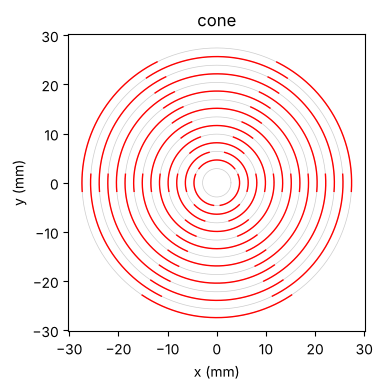

cone       42 cuts, 13503 vertices, narrowest ribbon 1.75 mm


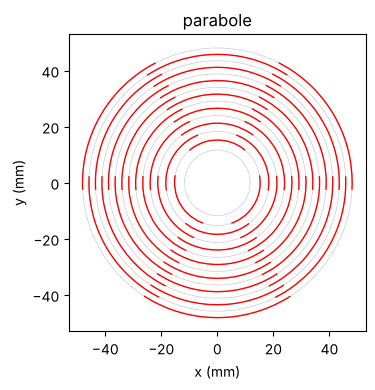

parabole   42 cuts, 23305 vertices, narrowest ribbon 2.29 mm


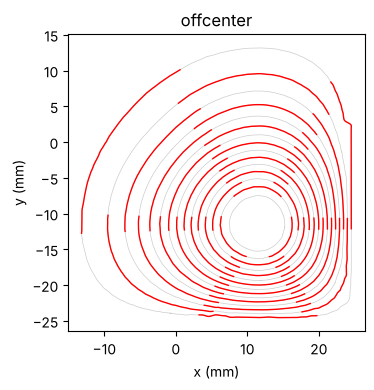

offcenter  42 cuts, 8928 vertices, narrowest ribbon 0.48 mm


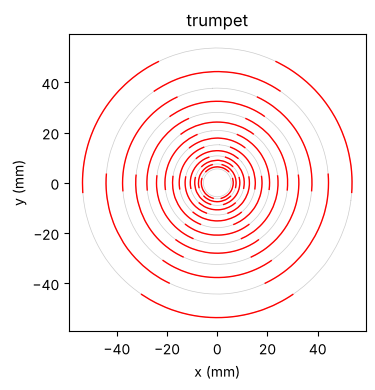

trumpet    42 cuts, 80254 vertices, narrowest ribbon 0.75 mm


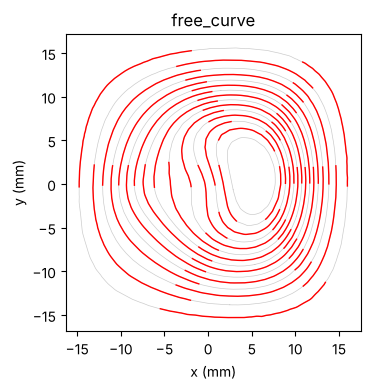

free_curve 42 cuts, 6903 vertices, narrowest ribbon 0.44 mm


In [4]:
for name in TARGETS:
    v, lines, heights = slice_target(name)
    spans = cutting_patern(lines, heights, N)
    plot_pattern(lines, spans, os.path.join(out, name+'_pattern.png'), name)
    widths = ribbon_widths(lines)
    sheet = kirigami_mesh(lines, heights, N, h = max(widths.min()/3, 0.5))
    save_sheet(os.path.join(out, name+'_sheet.npz'), sheet)
    os.replace(os.path.join(out, name+'_sheet.obj'), os.path.join(out, name+'_flat.obj'))
    print('%-10s %d cuts, %d vertices, narrowest ribbon %.2f mm' % (name, sum(len(s) for s in spans), len(sheet['V']), widths.min()))
    if widths.min() < 1.0:
        print('  warning: ribbons below 1 mm')
    if face_components(sheet['F']) > 1:
        print('  warning: the cuts split the sheet into %d pieces, try a lower TOP' % face_components(sheet['F']))

The flat sheets are written to `output/01_target_structures/<name>_flat.obj`, and the sheet data (mesh, rim, centre, cut edges) to `<name>_sheet.npz`.